# 05 펌프 센서 전체 기간 선형보간

1. 원본 데이터와 시간 간격 확인
2. 센서별 결측값 선형보간
3. 보완 전후 결측 집계 및 결과 CSV 검증
4. 센서별 전체 기간 그래프 확인

원본 데이터 전체를 시간 순서대로 사용합니다. `sensor_15`와 `sensor_50`은 제외합니다. 실행에는 `pandas`, `numpy`, `matplotlib`이 필요합니다.

## 1. 원본 데이터와 시간 간격 확인

원본의 시각과 행 순서를 유지합니다. 모든 대상 센서가 비어 있던 행의 개수를 아래에 표시합니다.

In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src" / "pump_missingness_audit.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소 또는 notebooks 폴더에서 실행하세요.")

sys.path.insert(0, str(project_root))
from src.pump_missingness_audit import MINUTE, default_source, missing_runs, read_sensor_data

source = default_source()
raw = read_sensor_data(source)
excluded = ["sensor_15", "sensor_50"]
sensor_columns = [column for column in raw if column.startswith("sensor_") and column not in excluded]
sensor_values = raw[sensor_columns].astype("float64")
timestamps = pd.to_datetime(raw["timestamp"], errors="raise")
if timestamps.isna().any() or not timestamps.diff().iloc[1:].eq(MINUTE).all():
    raise ValueError("시각이 결측이나 중복 없이 1분 간격으로 기록되었는지 확인하세요.")

missing = sensor_values.isna()
all_sensors_missing = missing.all(axis=1)
print(f"기록 기간 {timestamps.iloc[0]} ~ {timestamps.iloc[-1]}")
print(f"입력 {len(raw):,}행 · 대상 센서 {len(sensor_columns)}개")
print(f"대상 센서가 모두 결측이었던 행 {int(all_sensors_missing.sum()):,}개")

기록 기간 2018-04-01 00:00:00 ~ 2018-08-31 23:59:00
입력 220,320행 · 대상 센서 50개
대상 센서가 모두 결측이었던 행 11개


## 2. 센서별 결측값 선형보간

같은 센서에서 결측 구간 직전과 직후에 관측된 값을 잇고, 시각의 간격에 비례해 빈 값을 채웁니다. 이 데이터에서는 기간 양 끝에 결측값이 없으므로 외삽 없이 모든 결측을 채울 수 있습니다. 장기 결측도 같은 규칙으로 채웁니다. 그 구간에서 나타나는 직선은 보간 결과이며 실제 변화는 관측되지 않았습니다.

In [ ]:
# 날짜 인덱스로 보간한 뒤 원본 행 번호로 돌아옵니다.
indexed_values = sensor_values.set_axis(pd.DatetimeIndex(timestamps))
completed = indexed_values.interpolate(method="time", limit_area="inside")
completed = completed.set_axis(sensor_values.index)

completed_values = completed.to_numpy()
original_values = sensor_values.to_numpy()
missing_mask = missing.to_numpy()
assert np.array_equal(completed_values[~missing_mask], original_values[~missing_mask])
assert np.isfinite(completed_values).all(), "양 끝에 관측값이 없는 결측이 있는지 확인하세요."

# 일정한 1분 간격을 이용해 모든 보간값을 별도로 검산합니다.
for sensor in sensor_columns:
    gap = missing[sensor].to_numpy()
    positions = np.flatnonzero(gap)
    known = np.flatnonzero(~gap)
    expected = np.interp(positions, known, sensor_values[sensor].to_numpy()[known])
    np.testing.assert_allclose(completed[sensor].to_numpy()[positions], expected)

export_columns = ["timestamp", *sensor_columns, "machine_status"]
result = raw.loc[:, export_columns].copy()
result[sensor_columns] = completed

## 3. 보완 전후 결측 집계 및 결과 CSV 검증

센서별 결측 개수를 비교하고, 가장 긴 결측 구간을 확인합니다. 시각, 보완한 센서 50개, 설비 상태를 저장하고 다시 읽어 값이 일치하는지 검증합니다.

In [ ]:
summary = pd.DataFrame({
    "보완 전 결측": missing.sum(),
    "보완 후 결측": completed.isna().sum(),
}).sort_values("보완 전 결측", ascending=False, kind="stable")
print(f"결측이 있었던 센서 {int(summary['보완 전 결측'].gt(0).sum())}개")
print(f"센서 결측 {int(missing.sum().sum()):,} → {int(completed.isna().sum().sum()):,}셀")
display(summary)

time_missing = missing.set_axis(pd.DatetimeIndex(timestamps))
break_before = timestamps.diff().ne(MINUTE).set_axis(time_missing.index)
gap_summary = pd.concat([
    missing_runs(time_missing[sensor], break_before).assign(센서=sensor)
    for sensor in sensor_columns
], ignore_index=True)
if not gap_summary.empty:
    print("가장 긴 결측 구간")
    display(gap_summary.nlargest(1, "연속 결측(분)")[["센서", "시작", "종료", "연속 결측(분)"]])

결측이 있었던 센서 50개
센서 결측 47,237 → 0셀


,보완 전 결측,보완 후 결측
sensor_51,15383,0
sensor_00,10208,0
sensor_07,5451,0
sensor_08,5107,0
sensor_06,4798,0
sensor_09,4595,0
sensor_01,369,0
sensor_30,261,0
sensor_29,72,0
sensor_32,68,0


가장 긴 결측 구간


,센서,시작,종료,연속 결측(분)
440,sensor_51,2018-06-20 07:58:00,2018-06-30 23:53:00,15356


In [ ]:
output_path = project_root / "data/processed/sensor_linear_interpolation_full_period.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
temp_output = output_path.with_suffix(".csv.tmp")

# 재검증을 통과한 CSV만 최종 이름으로 교체합니다.
try:
    result.to_csv(temp_output, index=False)
    saved = pd.read_csv(temp_output, float_precision="round_trip")
    assert list(saved.columns) == export_columns
    assert len(saved) == len(raw)
    assert np.isfinite(saved[sensor_columns].to_numpy()).all()
    assert np.array_equal(saved[sensor_columns].to_numpy(), completed_values)
    for column in ("timestamp", "machine_status"):
        assert saved[column].equals(raw[column]), column
    temp_output.replace(output_path)
finally:
    temp_output.unlink(missing_ok=True)

print(f"저장: {output_path.relative_to(project_root).as_posix()}")
print(f"검증: {len(saved):,}행 · 센서 {len(sensor_columns)}개 · 센서 결측 0셀")

저장: data/processed/sensor_linear_interpolation_full_period.csv
검증: 220,320행 · 센서 50개 · 센서 결측 0셀


## 4. 센서별 전체 기간 그래프 확인

파란색은 원래 관측값, 주황색은 결측 위치에 새로 넣은 값입니다. 아래 띠는 원래 결측이었던 시점을 표시합니다. 전체 50개 그래프를 `figures/linear_interpolation_full_period/`에 PNG로 저장하고, 결측이 가장 많았던 센서를 아래에 표시합니다.

그래프 50개 저장: figures/linear_interpolation_full_period/


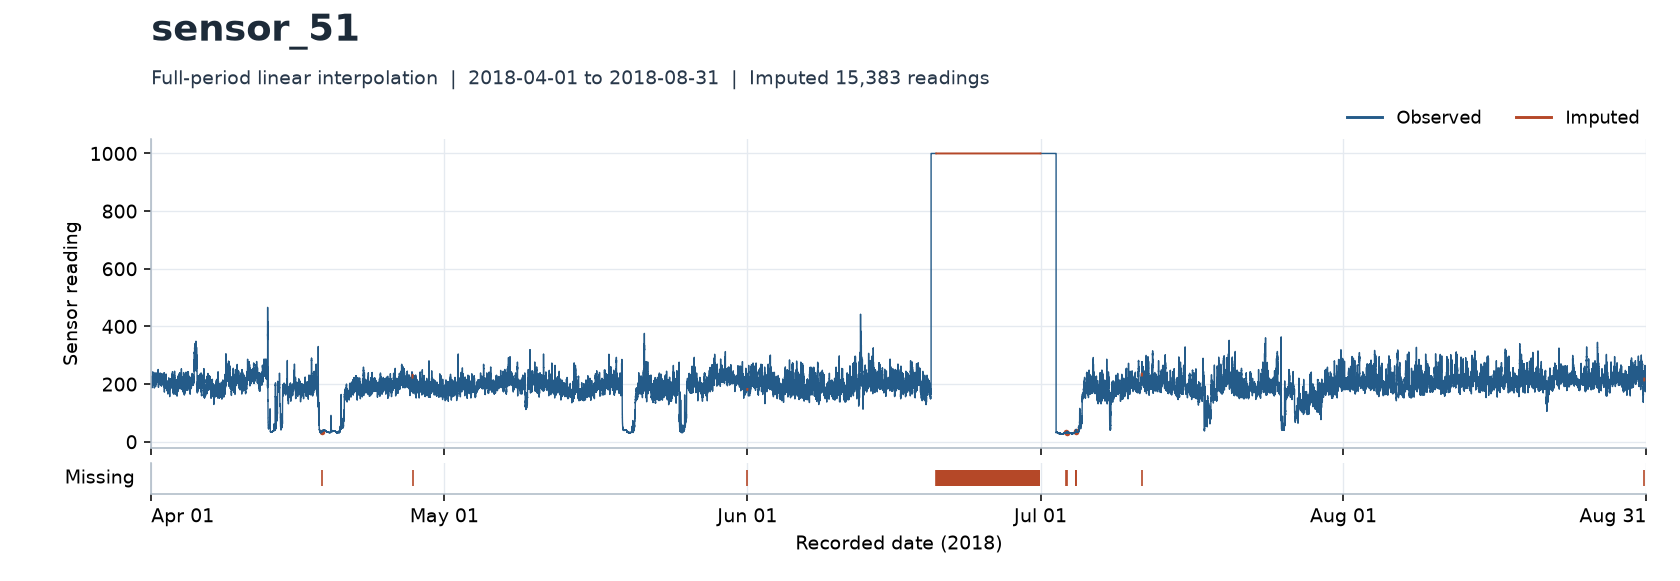

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Image
from matplotlib.lines import Line2D

figure_dir = project_root / "figures/linear_interpolation_full_period"
figure_dir.mkdir(parents=True, exist_ok=True)
start_time, end_time = timestamps.iloc[0], timestamps.iloc[-1]
elapsed = (timestamps - start_time) / pd.Timedelta(minutes=1)
ticks = pd.DatetimeIndex([start_time, *pd.date_range(start_time, end_time, freq="MS"), end_time]).unique()
tick_positions = (ticks - start_time) / pd.Timedelta(minutes=1)
observed_color, imputed_color = "#245b89", "#b54828"

def save_comparison_plot(sensor):
    """원본 관측값, 결측 위치의 추정값, 원본 결측 구간을 같은 시간축에 표시합니다."""
    missing_mask = missing[sensor].to_numpy()
    original = sensor_values[sensor].to_numpy()
    imputed = result[sensor].where(missing[sensor]).to_numpy()
    edges = np.flatnonzero(np.diff(np.r_[False, missing_mask, False]))
    starts, ends = edges[::2], edges[1::2]
    widths = ends - starts
    fig, (ax, gap_axis) = plt.subplots(
        2, 1, figsize=(12, 4.15), sharex=True,
        gridspec_kw={"height_ratios": [10, 1]},
    )
    fig.subplots_adjust(left=.09, right=.98, bottom=.15, top=.76, hspace=.09)
    fig.text(.09, .93, sensor, fontsize=19, fontweight="bold", color="#1d2b39")
    fig.text(
        .09, .855,
        f"Full-period linear interpolation  |  {start_time:%Y-%m-%d} to {end_time:%Y-%m-%d}"
        f"  |  Imputed {int(missing_mask.sum()):,} readings",
        fontsize=10, color="#28384a",
    )
    ax.plot(elapsed, original, color=observed_color, linewidth=.72)
    ax.plot(elapsed, imputed, color=imputed_color, linewidth=1.0)
    # 결측이 한 시점뿐인 경우에도 점으로 표시합니다.
    single = starts[widths == 1]
    if single.size:
        ax.scatter(elapsed.iloc[single], imputed[single], color=imputed_color, s=8, linewidths=0)
    handles = [
        Line2D([0], [0], color=observed_color, label="Observed"),
        Line2D([0], [0], color=imputed_color, label="Imputed"),
    ]
    ax.legend(handles=handles, loc="lower right", bbox_to_anchor=(1, 1.015),
              frameon=False, ncol=2, fontsize=9, borderaxespad=0)
    ax.set_ylabel("Sensor reading")
    ax.grid(True, color="#e5eaf0", linewidth=.7)
    ax.set_axisbelow(True)

    if starts.size:
        gap_axis.broken_barh(
            [(float(elapsed.iloc[start]) - .5, int(width)) for start, width in zip(starts, widths)],
            (.24, .52), facecolors=imputed_color, linewidth=0,
        )
        gap_axis.vlines(elapsed.iloc[starts], .24, .76, colors=imputed_color, linewidth=.85)
    gap_axis.set_ylim(0, 1)
    gap_axis.set_yticks([])
    gap_axis.set_ylabel("Missing", rotation=0, va="center", ha="right")
    gap_axis.yaxis.set_label_coords(-.011, .5)
    gap_axis.set_xticks(tick_positions, ticks.strftime("%b %d"))
    labels = gap_axis.get_xticklabels()
    labels[0].set_horizontalalignment("left")
    labels[-1].set_horizontalalignment("right")
    gap_axis.set_xlabel(f"Recorded date ({start_time:%Y})")
    gap_axis.set_xlim(-.5, float(elapsed.iloc[-1]) + .5)
    gap_axis.grid(True, axis="x", color="#e5eaf0", linewidth=.7)
    gap_axis.set_axisbelow(True)
    for axis in (ax, gap_axis):
        axis.spines[["top", "right"]].set_visible(False)
    try:
        fig.savefig(figure_dir / f"{sensor}.png", dpi=140, facecolor="white")
    finally:
        plt.close(fig)

# 원본 1분 측정값을 그대로 그립니다.
with plt.rc_context({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": "#aebac6", "path.simplify": False, "agg.path.chunksize": 10000,
}):
    for sensor in sensor_columns:
        save_comparison_plot(sensor)

print(f"그래프 {len(sensor_columns)}개 저장: {figure_dir.relative_to(project_root).as_posix()}/")
example_sensor = summary["보완 전 결측"].idxmax()
display(Image(filename=str(figure_dir / f"{example_sensor}.png"), width=950))